# Klasifikasi Status Pesanan Berpotensi Batal & Refund dengan Decision Tree
**SDG 12 – Target 12.3** (mengurangi food waste)

Pembagian data: **80% training / 20% testing**

## 1. Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## 2. Upload & Load Dataset
Jalankan sel ini lalu pilih file `data_bersih_v2.xlsx`.

In [ ]:
from google.colab import files
uploaded = files.upload()   # pilih file data Anda

nama_file = list(uploaded.keys())[0]   # ambil nama file apa adanya
print('File terbaca:', nama_file)

df = pd.read_excel(nama_file)
print('Ukuran data:', df.shape)
df.head()

Saving data bersih v2.xlsx to data bersih v2 (1).xlsx
File terbaca: data bersih v2 (1).xlsx
Ukuran data: (8500, 13)


,Harga_Pesanan,Jarak_Kirim_KM,Waktu_Tunggu_Menit,Rating_Pelanggan,Status_Promo,Tingkat_Keluhan,Kategori_Menu_Ayam,Kategori_Menu_Kopi,Kategori_Menu_Martabak,Kategori_Menu_Mie,Jam_Transaksi,Hari_Transaksi,Status_Pesanan_Encoded
0,10500,4.649558,21,4,0,0,False,True,False,False,0,0,0
1,18500,3.889618,17,5,0,0,False,False,True,False,0,0,0
2,48000,0.500000,12,3,1,1,True,False,False,False,1,0,0
3,51500,0.500000,15,5,0,0,True,False,False,False,1,0,0
4,18000,8.572622,23,5,1,0,False,True,False,False,1,0,0


Perbaiki Data

In [ ]:
# Cek nilai sebelum diubah
print("Sebelum:", df['Tingkat_Keluhan'].value_counts().sort_index().to_dict())

# Ubah 3 menjadi 2
df['Tingkat_Keluhan'] = df['Tingkat_Keluhan'].replace({3: 2})

# Cek nilai sesudah diubah
print("Sesudah:", df['Tingkat_Keluhan'].value_counts().sort_index().to_dict())

# Simpan sebagai file baru (opsional)
df.to_excel('data_bersih_v3.xlsx', index=False)
files.download('data_bersih_v3.xlsx')

Sebelum: {0: 5831, 1: 1643, 3: 1026}
Sesudah: {0: 5831, 1: 1643, 2: 1026}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. Cek Data & Distribusi Kelas Target

0 missing value
Harga_Pesanan               int64
Jarak_Kirim_KM            float64
Waktu_Tunggu_Menit          int64
Rating_Pelanggan            int64
Status_Promo                int64
Tingkat_Keluhan             int64
Kategori_Menu_Ayam           bool
Kategori_Menu_Kopi           bool
Kategori_Menu_Martabak       bool
Kategori_Menu_Mie            bool
Jam_Transaksi               int64
Hari_Transaksi              int64
Status_Pesanan_Encoded      int64
dtype: object 

                        Jumlah  Persen (%)
Status_Pesanan_Encoded                    
0                         7584       89.22
1                          611        7.19
2                          305        3.59


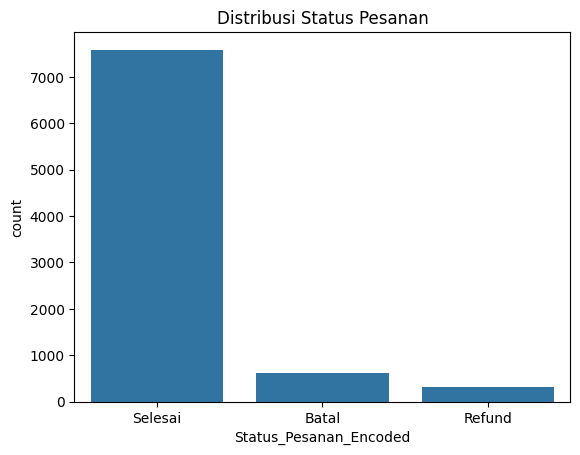

In [ ]:
print(df.isnull().sum().sum(), 'missing value')
print(df.dtypes, '\n')

TARGET = 'Status_Pesanan_Encoded'

# GANTI sesuai encoding pada preprocessing Anda
label_map = {0: 'Selesai', 1: 'Batal', 2: 'Refund'}

dist = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({'Jumlah': dist, 'Persen (%)': (dist / len(df) * 100).round(2)}))

sns.countplot(x=df[TARGET].map(label_map), order=list(label_map.values()))
plt.title('Distribusi Status Pesanan'); plt.show()

## 4. Pisahkan Fitur & Target, lalu Split 80:20
`stratify=y` menjaga proporsi kelas Batal/Refund tetap sama di data training dan testing (penting karena datanya tidak seimbang).

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% testing
    train_size=0.80,     # 80% training
    random_state=42,
    stratify=y
)

print(f'Data training : {X_train.shape[0]} ({X_train.shape[0]/len(df):.0%})')
print(f'Data testing  : {X_test.shape[0]} ({X_test.shape[0]/len(df):.0%})')

Data training : 6800 (80%)
Data testing  : 1700 (20%)


## 5. Training Model Baseline (Decision Tree default)

In [ ]:
dt_base = DecisionTreeClassifier(random_state=42)
dt_base.fit(X_train, y_train)

y_pred_base = dt_base.predict(X_test)
print('Akurasi training :', round(dt_base.score(X_train, y_train), 4))
print('Akurasi testing  :', round(accuracy_score(y_test, y_pred_base), 4))
print('Kedalaman pohon  :', dt_base.get_depth())

Akurasi training : 1.0
Akurasi testing  : 0.7906
Kedalaman pohon  : 31


> Jika akurasi training jauh lebih tinggi dari testing, model mengalami **overfitting**. Karena itu dilakukan tuning hyperparameter di bawah.

## 6. Tuning Hyperparameter (GridSearchCV)
Scoring memakai **F1-macro** agar kelas minoritas (Batal & Refund) ikut diperhitungkan, bukan hanya akurasi.

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 10, 30],
    'min_samples_leaf': [1, 5, 10, 20],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print('F1-macro (CV)    :', round(grid.best_score_, 4))

best_model = grid.best_estimator_

Parameter terbaik: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 20, 'min_samples_split': 2}
F1-macro (CV)    : 0.4102


## 7. Evaluasi pada Data Testing

In [ ]:
target_names = [label_map[k] for k in sorted(label_map)]

def evaluasi(model, nama):
    pred = model.predict(X_test)
    print(f'===== {nama} =====')
    print('Akurasi training:', round(model.score(X_train, y_train), 4))
    print('Akurasi testing :', round(accuracy_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=target_names, zero_division=0))
    return pred

pred_base = evaluasi(dt_base, 'Baseline')
pred_best = evaluasi(best_model, 'Model Tuning')

===== Baseline =====
Akurasi training: 1.0
Akurasi testing : 0.7906
              precision    recall  f1-score   support

     Selesai       0.90      0.87      0.89      1517
       Batal       0.10      0.11      0.10       122
      Refund       0.05      0.07      0.05        61

    accuracy                           0.79      1700
   macro avg       0.35      0.35      0.35      1700
weighted avg       0.82      0.79      0.80      1700

===== Model Tuning =====
Akurasi training: 0.771
Akurasi testing : 0.7629
              precision    recall  f1-score   support

     Selesai       0.92      0.82      0.87      1517
       Batal       0.23      0.41      0.29       122
      Refund       0.01      0.03      0.02        61

    accuracy                           0.76      1700
   macro avg       0.39      0.42      0.39      1700
weighted avg       0.84      0.76      0.80      1700



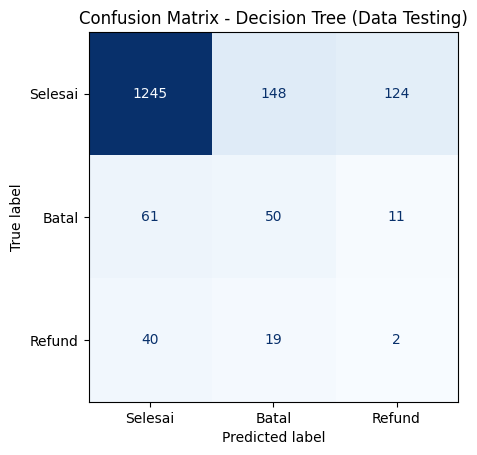

In [ ]:
cm = confusion_matrix(y_test, pred_best)
disp = ConfusionMatrixDisplay(cm, display_labels=target_names)
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix - Decision Tree (Data Testing)')
plt.show()

## 8. Feature Importance
Fitur apa yang paling berpengaruh terhadap pesanan berpotensi batal/refund.

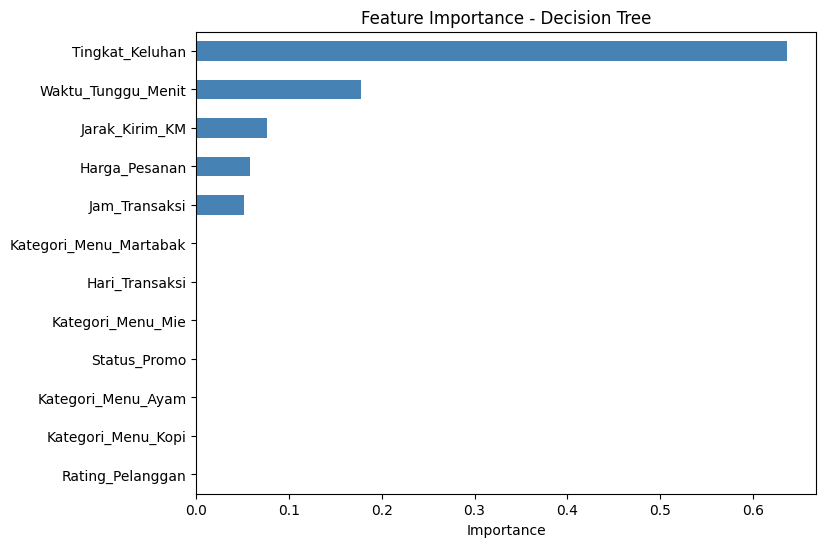

,0
Tingkat_Keluhan,0.6365
Waktu_Tunggu_Menit,0.1778
Jarak_Kirim_KM,0.0762
Harga_Pesanan,0.0580
Jam_Transaksi,0.0515
Kategori_Menu_Ayam,0.0000
Kategori_Menu_Kopi,0.0000
Rating_Pelanggan,0.0000
Status_Promo,0.0000
Kategori_Menu_Martabak,0.0000


In [ ]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.title('Feature Importance - Decision Tree'); plt.xlabel('Importance'); plt.show()
imp.sort_values(ascending=False).round(4)

## 9. Visualisasi Pohon Keputusan

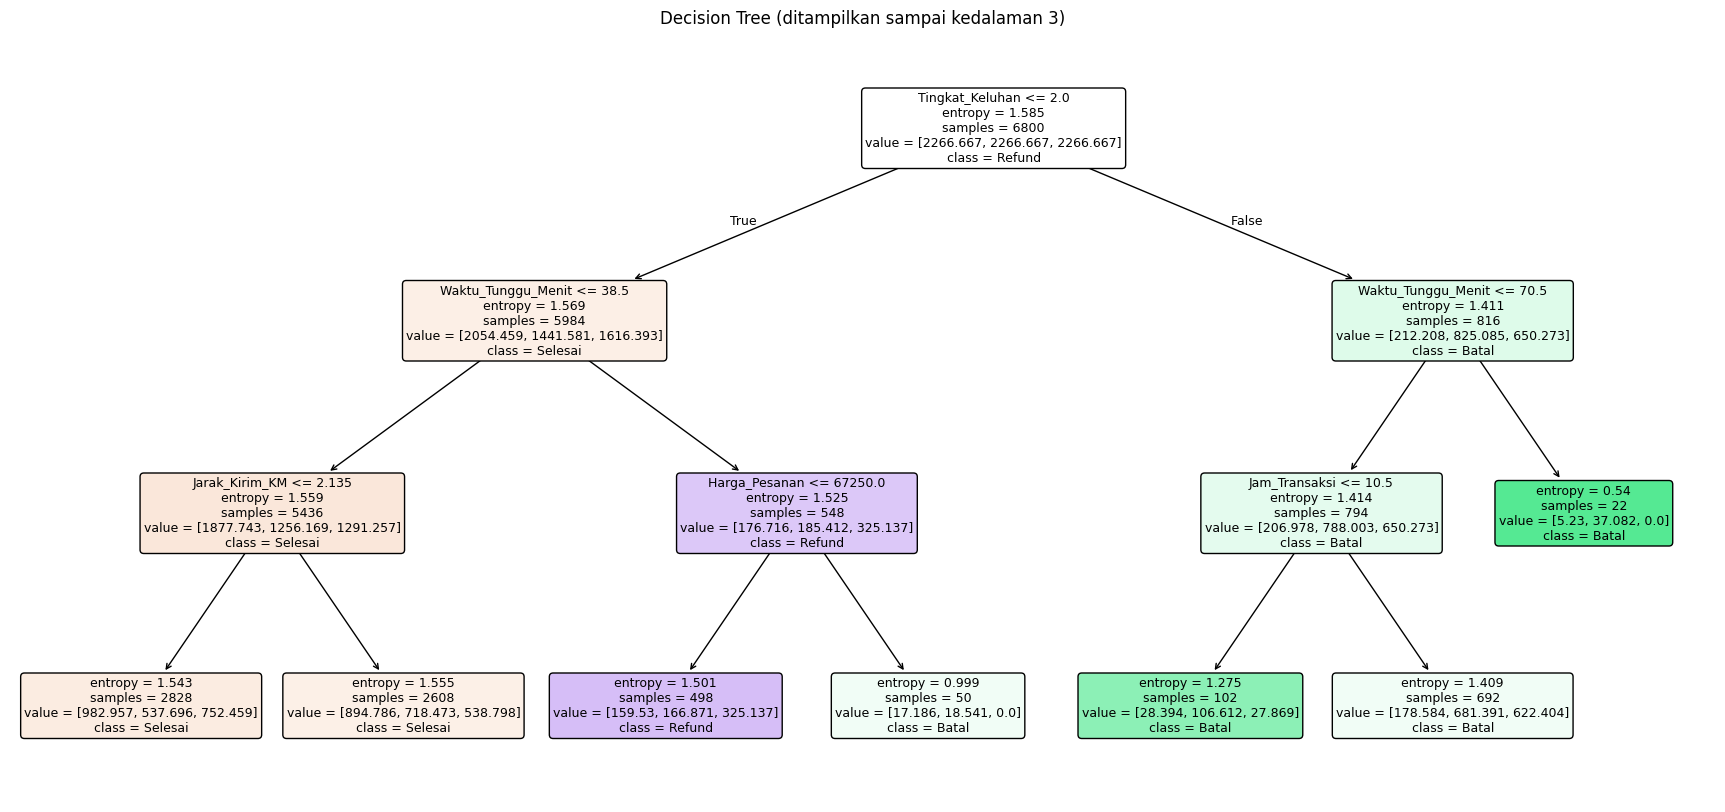

In [ ]:
plt.figure(figsize=(22, 10))
plot_tree(best_model, feature_names=X.columns, class_names=target_names,
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title('Decision Tree (ditampilkan sampai kedalaman 3)')
plt.show()

## 10. Simpan Model

In [ ]:
joblib.dump(best_model, 'model_decision_tree.pkl')
files.download('model_decision_tree.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

# Ensure sample_data directory exists
os.makedirs('/content/sample_data', exist_ok=True)

# Combine X_test and y_test to save the complete 20% testing dataset
test_df = X_test.copy()
test_df[TARGET] = y_test

# Save to sample_data directory
test_df.to_excel('/content/sample_data/data_testing_20.xlsx', index=False)
print('Dataset testing 20% berhasil disimpan di /content/sample_data/data_testing_20.xlsx')

Dataset testing 20% berhasil disimpan di /content/sample_data/data_testing_20.xlsx


In [ ]:
# Combine X_train and y_train to save the 80% training dataset
train_df = X_train.copy()
train_df[TARGET] = y_train

# Save to excel
train_df.to_excel('data_training_80.xlsx', index=False)
print('Dataset training 80% berhasil disimpan sebagai data_training_80.xlsx')

Dataset training 80% berhasil disimpan sebagai data_training_80.xlsx


## 11. Contoh Prediksi Pesanan Baru

In [ ]:
contoh = X_test.iloc[[0]]
print(contoh.T, '\n')
hasil = best_model.predict(contoh)[0]
proba = best_model.predict_proba(contoh)[0]
print('Prediksi :', label_map[hasil])
print('Probabilitas:', {label_map[k]: round(p, 3) for k, p in zip(best_model.classes_, proba)})

                            3703
Harga_Pesanan            1514500
Jarak_Kirim_KM          0.670241
Waktu_Tunggu_Menit            12
Rating_Pelanggan               5
Status_Promo                   1
Tingkat_Keluhan                0
Kategori_Menu_Ayam          True
Kategori_Menu_Kopi         False
Kategori_Menu_Martabak     False
Kategori_Menu_Mie          False
Jam_Transaksi                 17
Hari_Transaksi                 4 

Prediksi : Selesai
Probabilitas: {'Selesai': np.float64(0.432), 'Batal': np.float64(0.237), 'Refund': np.float64(0.331)}


## 12. Inference dengan Input Manual
Jalankan sel di bawah, lalu isi data pesanan satu per satu. Tekan Enter tanpa mengetik apa pun untuk memakai nilai default di dalam tanda kurung.

In [ ]:
import joblib
import os
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

def minta_angka(pesan, tipe=float, minimum=None, maksimum=None, default=None):
    """Meminta input angka dan mengulang jika tidak valid."""
    while True:
        teks = input(f"{pesan}" + (f" [default {default}]" if default is not None else "") + ": ").strip()
        if teks == "" and default is not None:
            return default
        try:
            nilai = tipe(teks)
        except ValueError:
            print("  ! Masukkan angka yang valid.")
            continue
        if (minimum is not None and nilai < minimum) or (maksimum is not None and nilai > maksimum):
            print(f"  ! Nilai harus antara {minimum} dan {maksimum}.")
            continue
        return nilai


def input_pesanan_manual(kolom_fitur):
    print("=== INPUT DATA PESANAN ===")
    harga   = minta_angka("Harga pesanan (Rp)", int, 0, default=50000)
    jarak   = minta_angka("Jarak kirim (KM, 0.5 - 25)", float, 0, 25, default=5.0)
    tunggu  = minta_angka("Waktu tunggu (menit, 5 - 112)", int, 0, 200, default=30)
    rating  = minta_angka("Rating pelanggan (1 - 5)", int, 1, 5, default=4)
    promo   = minta_angka("Memakai promo? (0 = Tidak, 1 = Ya)", int, 0, 1, default=0)
    keluhan = minta_angka("Tingkat keluhan (0 - 2)", int, 0, 2, default=0)
    jam     = minta_angka("Jam transaksi (0 - 23)", int, 0, 23, default=12)
    hari    = minta_angka("Hari transaksi (0 - 6)", int, 0, 6, default=0)

    print("\nKategori menu: 1 = Ayam, 2 = Kopi, 3 = Martabak, 4 = Mie, 5 = Lainnya")
    menu = minta_angka("Pilih kategori menu (1 - 5)", int, 1, 5, default=5)

    data = {
        "Harga_Pesanan": harga,
        "Jarak_Kirim_KM": jarak,
        "Waktu_Tunggu_Menit": tunggu,
        "Rating_Pelanggan": rating,
        "Status_Promo": promo,
        "Tingkat_Keluhan": keluhan,
        "Kategori_Menu_Ayam": menu == 1,
        "Kategori_Menu_Kopi": menu == 2,
        "Kategori_Menu_Martabak": menu == 3,
        "Kategori_Menu_Mie": menu == 4,
        "Jam_Transaksi": jam,
        "Hari_Transaksi": hari,
    }
    return pd.DataFrame([data])[kolom_fitur]


def prediksi_pesanan():
    global best_model
    model = None

    # 1. Cek model di global
    if 'best_model' in globals():
        model = best_model
    # 2. Cek model di file
    elif os.path.exists('model_decision_tree.pkl'):
        print("Memuat model dari 'model_decision_tree.pkl'...")
        model = joblib.load('model_decision_tree.pkl')
    # 3. Latih ulang otomatis jika file data tersedia
    elif os.path.exists('/content/data_bersih_v3.xlsx'):
        print("Model tidak ditemukan di memori. Melatih ulang model otomatis dari data_bersih_v3.xlsx...")
        df_temp = pd.read_excel('/content/data_bersih_v3.xlsx')
        X_temp = df_temp.drop(columns=['Status_Pesanan_Encoded'])
        y_temp = df_temp['Status_Pesanan_Encoded']

        # Gunakan parameter terbaik hasil Tuning Hyperparameter sebelumnya
        model = DecisionTreeClassifier(
            class_weight='balanced',
            criterion='entropy',
            max_depth=3,
            min_samples_leaf=20,
            min_samples_split=2,
            random_state=42
        )
        model.fit(X_temp, y_temp)
        best_model = model
        joblib.dump(model, 'model_decision_tree.pkl')
    else:
        raise FileNotFoundError("Model maupun dataset 'data_bersih_v3.xlsx' tidak ditemukan. Harap jalankan sel preprocessing dan training terlebih dahulu.")

    # Menentukan urutan kolom fitur yang benar
    if 'X' in globals():
        kolom_fitur = X.columns
    elif os.path.exists('/content/data_bersih_v3.xlsx'):
        df_temp = pd.read_excel('/content/data_bersih_v3.xlsx')
        kolom_fitur = df_temp.drop(columns=['Status_Pesanan_Encoded']).columns
    else:
        kolom_fitur = [
            "Harga_Pesanan", "Jarak_Kirim_KM", "Waktu_Tunggu_Menit", "Rating_Pelanggan",
            "Status_Promo", "Tingkat_Keluhan", "Kategori_Menu_Ayam", "Kategori_Menu_Kopi",
            "Kategori_Menu_Martabak", "Kategori_Menu_Mie", "Jam_Transaksi", "Hari_Transaksi"
        ]

    pesanan = input_pesanan_manual(kolom_fitur)
    kelas = model.predict(pesanan)[0]
    proba = model.predict_proba(pesanan)[0]

    # Menentukan label map
    peta_label = label_map if 'label_map' in globals() else {0: 'Selesai', 1: 'Batal', 2: 'Refund'}

    print("\n=== HASIL PREDIKSI ===")
    print("Status prediksi :", peta_label[kelas])
    for k, p in zip(model.classes_, proba):
        print(f"  Probabilitas {peta_label[k]:<8}: {p:.1%}")

    if kelas == 0:
        print("\nKesimpulan: pesanan diprediksi AMAN diselesaikan.")
    else:
        print(f"\nPERINGATAN: pesanan berpotensi {peta_label[kelas].upper()}.")
        print("Saran: konfirmasi ke pelanggan / tunda produksi makanan agar tidak terbuang.")

prediksi_pesanan()

Model tidak ditemukan di memori. Melatih ulang model otomatis dari data_bersih_v3.xlsx...
=== INPUT DATA PESANAN ===
Harga pesanan (Rp) [default 50000]: 9000
Jarak kirim (KM, 0.5 - 25) [default 5.0]: 2
Waktu tunggu (menit, 5 - 112) [default 30]: 27
Rating pelanggan (1 - 5) [default 4]: 4
Memakai promo? (0 = Tidak, 1 = Ya) [default 0]: 0
Tingkat keluhan (0 - 2) [default 0]: 0
Jam transaksi (0 - 23) [default 12]: 13
Hari transaksi (0 - 6) [default 0]: 3

Kategori menu: 1 = Ayam, 2 = Kopi, 3 = Martabak, 4 = Mie, 5 = Lainnya
Pilih kategori menu (1 - 5) [default 5]: 2

=== HASIL PREDIKSI ===
Status prediksi : Selesai
  Probabilitas Selesai : 42.4%
  Probabilitas Batal   : 27.6%
  Probabilitas Refund  : 30.0%

Kesimpulan: pesanan diprediksi AMAN diselesaikan.
